# 06 · Final forecast and inventory decisions

**What:** refit every candidate on all 277 weeks; forecast 13 weeks ahead (2016-05-21 to 2016-08-13) with 80/95% intervals; convert forecasts into safety stock, reorder points and order-up-to levels; back-test the replenishment policies in a simulation.
**Why refit on everything:** the holdout has done its job (an honest accuracy estimate). Leaving out the latest 13 weeks at deployment would ignore the most relevant information. The **model choice** is not changed: it was fixed on CV.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
def show(fig): display(Image(filename=f"reports/figures/{fig}"))
def J(path): return json.load(open(path))

## 1. Forward forecast

{'best_model_by_level_cv': {'category': 'DHR-ARIMA', 'department': 'SARIMA', 'sku_store': 'Ensemble', 'store': 'DHR-ARIMA', 'store_dept': 'Ensemble', 'total': 'DHR-ARIMA'}, 'forecast_window': ['2016-05-21', '2016-08-13']}


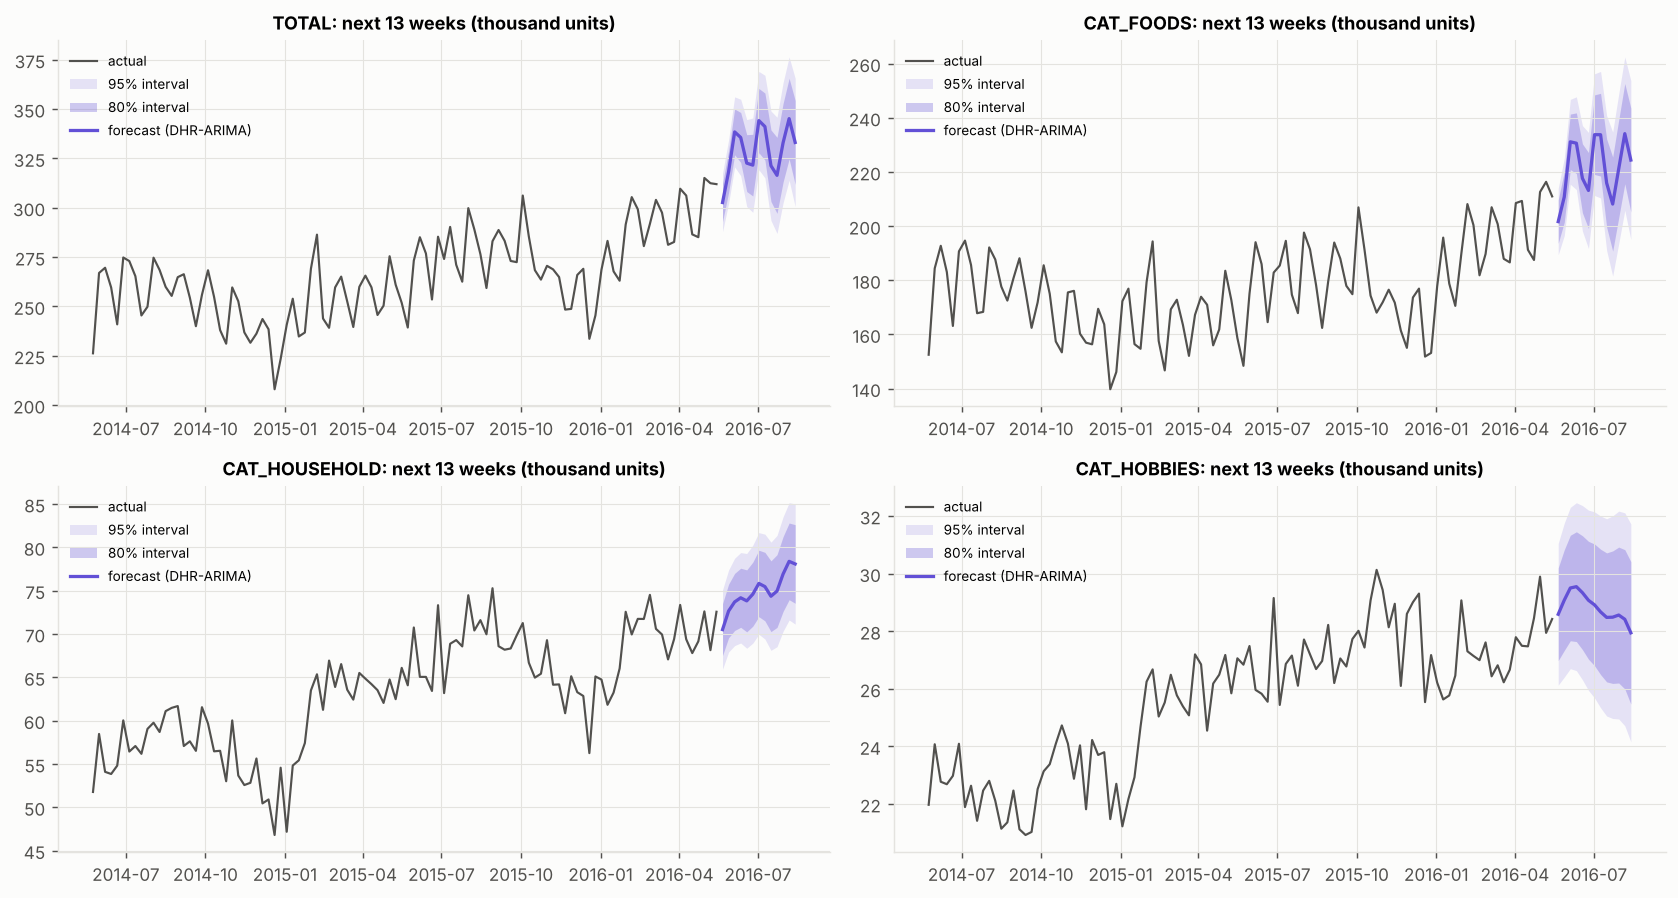

,unique_id,model,total_13w,peak_week,last_13w_actual,same_13w_last_year_actual,vs_same_period_last_year_pct
0,CAT_FOODS,DHR-ARIMA,2876614.1,2016-08-06,2590528.0,2340820.0,22.9
1,CAT_HOBBIES,DHR-ARIMA,374588.5,2016-06-11,358220.0,347978.0,7.6
2,CAT_HOUSEHOLD,DHR-ARIMA,973404.6,2016-08-06,916234.0,888029.0,9.6
3,TOTAL,DHR-ARIMA,4273601.7,2016-08-06,3864982.0,3576827.0,19.5


In [2]:
print(J("reports/final_forecast_summary.json"))
show("14_final_forecast.png")
display(pd.read_csv("reports/tables/final_forecast_headline.csv").round(1))

**Model per series = best mean CV MASE at its level**: DHR-ARIMA for total, category and store; SARIMA for departments; Ensemble for store x department and SKUs.

**What the forecast says:** total demand of about **4.27 M units** over the next 13 weeks, **+19.5% vs the same 13 weeks of 2015**. That is consistent with the last 13 actual weeks, which were already +16.2% year on year, and with SARIMA, ETS and the Ensemble giving similar levels. FOODS drives the growth (+22.9%); HOUSEHOLD +9.6%, HOBBIES +7.6%. Weekly peaks fall in the SNAP-heavy first weeks of each month and in early August.
**What it does NOT say:** it knows nothing about future promotions, competitor actions, supply disruptions or new-store openings; prices are assumed unchanged; and the intervals reflect only the variability seen in the past. The CV evidence says that, for the total, a 13-week WAPE of about 2-4% is typical, and that the nominal 80% intervals are roughly calibrated at aggregate level for SARIMA/DHR.

## 2. Inventory policy
- **Safety stock** SS = z · σ · √(L + R) and **order-up-to** S = forecast over L + R weeks + SS (periodic review, R = 1 week); **reorder point** ROP = forecast over L + z · σ · √L.
- **σ is the standard deviation of the model's own forecast errors** (RMSE of CV errors at horizons 1-4), **not** of demand: the forecast already explains trend and seasonality, so only the unexplained part needs buffering.
- **z = Φ⁻¹(service level)**: 1.645 for 95%.
- Lead time is an **assumption** (M5 has none): sensitivity for 1-4 weeks and service levels 90/95/98%. Costs: holding 1 per unit-week, shortage 9 per lost unit (assumed).

,group,policy,fill_rate,stockout_rate,avg_on_hand,safety_stock,total_cost,total_cost_vs_SeasonalNaive_pct,avg_on_hand_vs_SeasonalNaive_pct
4,SKU,Ensemble,0.936,0.072,2071.813,1782.813,35154.878,-42.833,-44.003
16,SKU,Ensemble + demand-sigma,0.952,0.058,2408.897,2168.297,37399.549,-39.183,-34.892
28,SKU,LightGBM,0.943,0.071,2157.705,1858.656,35382.123,-42.464,-41.681
40,SKU,Naive,0.950,0.048,2931.468,2214.326,44535.046,-27.580,-20.768
52,SKU,SARIMA,0.932,0.076,2218.272,1909.475,37563.183,-38.917,-40.044
64,SKU,SeasonalNaive,0.895,0.097,3699.838,3314.831,61495.521,0.000,0.000
76,store_dept,Ensemble,0.994,0.076,75287.240,68792.669,1181936.275,-55.361,29.007
88,store_dept,Ensemble + demand-sigma,0.998,0.046,95822.517,92133.511,1323524.133,-50.014,64.195
100,store_dept,LightGBM,0.995,0.065,95265.329,82872.773,1417931.958,-46.448,63.240
112,store_dept,Naive,0.978,0.124,96379.167,84674.660,2007390.415,-24.186,65.149


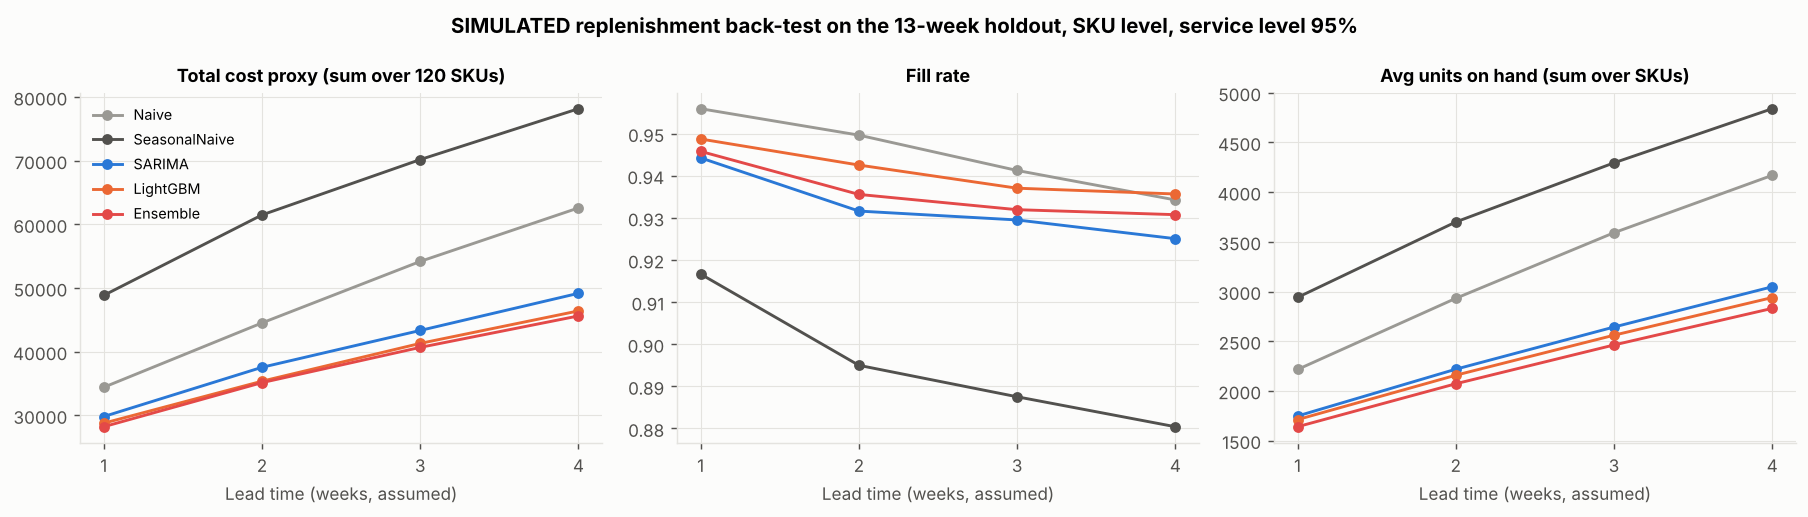

In [3]:
s = pd.read_csv("reports/tables/inventory_simulation_summary.csv")
d = s[(s.lead_time == 2) & (s.service_level == 0.95)]
display(d[["group", "policy", "fill_rate", "stockout_rate", "avg_on_hand", "safety_stock", "total_cost", "total_cost_vs_SeasonalNaive_pct", "avg_on_hand_vs_SeasonalNaive_pct"]].round(3))
show("15_inventory_sensitivity.png")

**SIMULATED, under stated assumptions; these are not real savings.** At L = 2 weeks and 95% service:
- **SKUs (120):** the Ensemble-driven policy has a cost proxy **42.8% lower** than the seasonal-naive policy (fill rate 93.6% vs 89.5%, average stock 44% lower). LightGBM −42.5%, SARIMA −38.9%. Naive reaches the highest fill (95.0%) but holds 41% more stock than the Ensemble policy.
- **Store x department (70):** Ensemble −55.4%, SARIMA −55.8%, LightGBM −46.4% vs seasonal naive, whose 11% under-forecast during growth causes a 24.9% weekly stock-out rate.
- The ranking is **identical across all 12 lead-time x service-level combinations** (SKU savings 37-43%, store x department 43-66%).

**Honest caveats:** (1) much of the gain vs seasonal naive comes from that baseline's growth bias in a +16% YoY quarter; (2) at SKU level the policies under-deliver the 95% target (weekly stock-out rate 6.1-7.9% vs 5%), because σ comes from only 16 CV errors per series, the √(L+R) rule ignores error autocorrelation, and censored zero-runs understate demand variability; (3) 13 weeks is a short window.

In [4]:
ds_ = s[(s.lead_time == 2) & (s.service_level == 0.95) & s.policy.str.contains("demand-sigma|Ensemble")]
display(ds_[["group", "policy", "safety_stock", "avg_on_hand", "fill_rate", "total_cost"]].round(1))

,group,policy,safety_stock,avg_on_hand,fill_rate,total_cost
4,SKU,Ensemble,1782.8,2071.8,0.9,35154.9
16,SKU,Ensemble + demand-sigma,2168.3,2408.9,1.0,37399.5
76,store_dept,Ensemble,68792.7,75287.2,1.0,1181936.3
88,store_dept,Ensemble + demand-sigma,92133.5,95822.5,1.0,1323524.1


**Why σ must come from forecast error:** with the same Ensemble forecasts, sizing safety stock on raw demand variability (`+ demand-sigma`) raises total safety stock by 34% at store x department (92k vs 69k units) and average on-hand by 27%. Fill improves marginally (99.8% vs 99.4%), but the total cost proxy is 12% higher. Seasonality and trend are predictable, so buffering against them is wasted stock.

## 3. At-risk list (replenishment / merchandising actions)

In [5]:
r = pd.read_csv("outputs/inventory_recommendations.csv")
print(r.risk.value_counts())
for k in ["STOCK-OUT RISK", "OVERSTOCK RISK"]:
    display(Markdown(f"**{k}** (top 8)"))
    display(r[r.risk == k].sort_values("risk_score", ascending=False).head(8)[["unique_id", "sbc_class", "cv_bias", "sim_fill_rate", "sim_weeks_of_cover", "safety_stock", "reorder_point", "order_up_to_level"]].round(2))

risk
ok                84
STOCK-OUT RISK    57
OVERSTOCK RISK    49
Name: count, dtype: int64


**STOCK-OUT RISK** (top 8)

,unique_id,sbc_class,cv_bias,sim_fill_rate,sim_weeks_of_cover,safety_stock,reorder_point,order_up_to_level
49,SKU_FOODS_2_029_WI_2,lumpy,-0.39,0.76,0.66,27.53,64.61,101.19
50,SKU_HOUSEHOLD_2_054_WI_3,erratic,-0.59,1.00,0.90,4.41,13.21,18.78
51,SKU_FOODS_3_757_CA_1,intermittent,-0.16,0.72,0.57,14.73,107.46,155.50
52,SKU_HOUSEHOLD_2_176_CA_3,smooth,-0.26,0.84,0.57,21.36,135.28,193.90
53,SKU_FOODS_3_594_TX_3,erratic,-0.40,1.00,16.80,72.07,83.70,114.86
54,SKU_FOODS_1_110_TX_3,smooth,0.14,0.61,5.42,27.05,104.79,143.71
55,SKU_HOBBIES_2_113_WI_1,lumpy,-0.38,1.00,14.82,7.28,8.63,11.24
56,SKU_HOBBIES_1_133_CA_3,smooth,0.22,0.62,2.15,2.26,9.46,14.12


**OVERSTOCK RISK** (top 8)

,unique_id,sbc_class,cv_bias,sim_fill_rate,sim_weeks_of_cover,safety_stock,reorder_point,order_up_to_level
0,SKU_FOODS_1_197_WI_3,intermittent,0.86,1.0,15.51,1.41,2.24,3.12
1,SKU_FOODS_2_032_TX_3,intermittent,0.23,1.0,18.66,11.85,24.58,34.80
2,SKU_FOODS_2_229_CA_3,lumpy,0.24,1.0,17.53,6.43,13.38,18.17
3,SKU_HOUSEHOLD_2_198_CA_4,intermittent,1.25,1.0,3.72,2.19,3.76,5.17
4,SKU_HOUSEHOLD_2_207_TX_3,intermittent,0.63,1.0,9.44,1.75,2.75,3.75
5,SKU_HOBBIES_2_019_CA_2,lumpy,-0.10,1.0,14.62,2.95,3.61,4.61
6,SKU_HOUSEHOLD_2_138_CA_1,intermittent,0.42,1.0,10.00,3.25,5.22,7.04
7,SKU_FOODS_3_271_TX_3,erratic,-0.02,1.0,12.46,14.85,19.31,24.84


**Business reading**
- **Stock-out risk** (simulated fill < 90% or CV bias < −10%): mostly lumpy/erratic SKUs whose forecasts run low (e.g. a lumpy WI_2 FOODS SKU with −39% CV bias and 76% simulated fill). *Action:* raise the safety factor or move to a demand-sensing / min-max rule for these items, check for unrecorded stock-outs (censoring), and review the planogram presentation minimum.
- **Overstock risk** (cover > 3 weeks or CV bias > +10%): mostly slow intermittent SKUs where the order-up-to logic holds 10-18 weeks of cover because a single unit is a large share of weekly demand. *Action:* switch these to a fixed minimum presentation quantity / order-multiple policy or to an intermittent-demand method (Croston/TSB), and consider range rationalisation for chronically slow lines.
- In fashion retail (Westside / Zudio type assortments), the same split maps to **core basics** (aggregate-like, forecast with SARIMA/DHR at store x category and allocate down) versus **long-tail SKU-size options** (global ML model + intermittent-demand inventory rules).